# Lab: Relationships Between Quantitative Features

Use a historical mammal sleep dataset to compare dreaming, non-dreaming, and total sleep. Use non-dreaming versus total sleep as the main model, then examine whether danger and predation ratings add information. Finally, investigate the nonlinear pattern between gestation time and total sleep.

Support conclusions with the plots and calculations. Explain how well a straight line follows the points and how much variation remains.

## Learning goals

- Describe whether points trend upward or downward, follow a straight or curved pattern, cluster closely around that pattern, or include unusual observations.
- Calculate correlation and interpret R-squared on the correct response scale.
- Recognize nonlinear patterns and compare original gestation with log-transformed gestation.
- Examine additional categorical features visually and compare model R-squared on the same observations.
- Check missing codes, units, category counts, and transformations.
- Distinguish improved fit to observed records from causation and performance on new data.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can answer it?
3. **Evidence:** What should we calculate and display?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete each investigation in order. Use separate cells for individual operations and add cells as needed. Give figures informative titles, named colors, and axis labels with units or transformations. Use the default point transparency and line widths. `ci=None` can omit confidence bands so the patterns and group lines are easier to compare.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code and checking every claim against the source and your output. Complete the AI-use reflection at the end.

## Dataset and context

Use the [StatLib mammal sleep data hosted by UC Berkeley](https://www.stat.berkeley.edu/~spector/s100/data/sleep.dat) and its [measurement dictionary](https://www.stat.berkeley.edu/~spector/s100/data/sleep.html). A local copy is supplied as `data/mammal_sleep.csv`.

The supplied `data/mammal_sleep.csv` contains all 62 records and 11 features, including species names and both sleep phases. One row describes a mammal species, not an individual animal or a night. The data trace to Allison and Cicchetti's 1976 study, [Sleep in mammals: ecological and constitutional correlates](https://pubmed.ncbi.nlm.nih.gov/982039/). This is a historical comparative dataset, not a random sample of all mammals; individual collection dates are not supplied.

Course preparation preserves all values and names, gives columns descriptive names, and converts the source's `-999` missing code into blank CSV fields. Use ordinary `pd.read_csv()`; blanks are recognized as missing. The terms dreaming and non-dreaming identify the study's sleep-phase measurements; they are not direct reports of an animal's subjective dream experiences.

### Data dictionary

| Feature | Meaning and units or codes |
| --- | --- |
| `species` | Species label as recorded in the historical source |
| `non_dreaming_sleep` | Non-dreaming sleep in hours per day |
| `dreaming_sleep` | Dreaming sleep in hours per day |
| `body_weight` | Body weight in kilograms |
| `brain_weight` | Brain weight in grams |
| `max_life_span` | Maximum lifespan in years |
| `gestation_time` | Gestation duration in days |
| `predation_index` | Ordered rating, 1–5: lower to higher likelihood of being preyed upon |
| `sleep_exposure_index` | Ordered rating, 1–5: more protected to more exposed sleeping conditions |
| `danger_index` | Ordered rating, 1–5: lower to higher overall danger from other animals |
| `total_sleep` | Total sleep in hours per day; sum of the two phases |

The indices are **ordinal categorical features**, even though stored as numbers. A one-point difference is not a documented equal increment of physical risk. Overall danger incorporates predation, sleep exposure, and other information, so these ratings are not independent measurements. In our models, represent rating levels as categories rather than assuming equal numerical spacing.

## Load and inspect the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
mammals_df = pd.read_csv("data/mammal_sleep.csv")

In [3]:
mammals_df.head()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
0,African elephant,6654.000,5712.0,NaN,NaN,3.3,38.6,645.0,3,5,3
1,African giant pouched rat,1.000,6.6,6.3,2.0,8.3,4.5,42.0,3,1,3
2,Arctic Fox,3.385,44.5,NaN,NaN,12.5,14.0,60.0,1,1,1
3,Arctic ground squirrel,0.920,5.7,NaN,NaN,16.5,NaN,25.0,5,2,3
4,Asian elephant,2547.000,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4


In [4]:
mammals_df.tail()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
57,Tree hyrax,2.000,12.3,4.9,0.5,5.4,7.5,200.0,3,1,3
58,Tree shrew,0.104,2.5,13.2,2.6,15.8,2.3,46.0,3,2,2
59,Vervet,4.190,58.0,9.7,0.6,10.3,24.0,210.0,4,3,4
60,Water opossum,3.500,3.9,12.8,6.6,19.4,3.0,14.0,2,1,1
61,Yellow-bellied marmot,4.050,17.0,NaN,NaN,NaN,13.0,38.0,3,1,1


In [5]:
mammals_df.shape

(62, 11)

In [6]:
mammals_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   species               62 non-null     str    
 1   body_weight           62 non-null     float64
 2   brain_weight          62 non-null     float64
 3   non_dreaming_sleep    48 non-null     float64
 4   dreaming_sleep        50 non-null     float64
 5   total_sleep           58 non-null     float64
 6   max_life_span         58 non-null     float64
 7   gestation_time        58 non-null     float64
 8   predation_index       62 non-null     int64  
 9   sleep_exposure_index  62 non-null     int64  
 10  danger_index          62 non-null     int64  
dtypes: float64(7), int64(3), str(1)
memory usage: 6.1 KB


In [7]:
mammals_df.isna().sum()

species                  0
body_weight              0
brain_weight             0
non_dreaming_sleep      14
dreaming_sleep          12
total_sleep              4
max_life_span            4
gestation_time           4
predation_index          0
sleep_exposure_index     0
danger_index             0
dtype: int64

**What does one row represent?**

Your answer:One row represents one mammal species in the historical dataset, rather than an individual animal or a single night of sleep.

**Complete the table using the data dictionary, `.info()`, and `.isnull().sum()`. For data type, use categorical or quantitative. For data storage type, report the Pandas dtype. For missing values, report the count, including 0 when none are missing.**

| Feature | Data type | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `species` | Categorical  | str | 0 |
| `non_dreaming_sleep` | Quantitative | float64 | 14 |
| `dreaming_sleep` | Quantitative | float64 | 12 |
| `body_weight` | Quantitative | float64 | 0 |
| `brain_weight` | Quantitative | float64 | 0 |
| `max_life_span` | Quantitative | float64 | 0 |
| `gestation_time` | Quantitative | float64 | 0 |
| `predation_index` | Categotical | int64 | 0 |
| `sleep_exposure_index` | Categorical | int64 | 0 |
| `danger_index` | Categorical | int64 | 0 |
| `total_sleep` | Quantitative | float64 | 4 |

Your answer:

# Investigation 1: Dreaming, non-dreaming, and total sleep

## Step 1: Question

**How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?**

Compare three relationships in hours per day: dreaming versus non-dreaming, dreaming versus total, and non-dreaming versus total. In the last comparison, use non-dreaming sleep on the horizontal axis and total sleep as the response. This is the main model for Investigation 2.

**Predict the direction and strength of each relationship. Which phase do you expect to be more strongly related to total sleep, and why?**

Your answer:I predict positive relationships between dreaming and non-dreaming sleep and between each phase and total sleep. I expect non-dreaming sleep to have the stronger linear relationship with total sleep because it likely accounts for more of the variation in total sleep. I am less certain about the strength of the relationship between the two phases. Since total sleep is the sum of both phases, relationships with total sleep partly reflect this mathematical connection.

## Step 2: Data

Create `sleep_df` from records complete for `dreaming_sleep`, `non_dreaming_sleep`, `total_sleep`, `danger_index`, and `predation_index`. Use `.copy()` and keep `mammals_df` unchanged. Use this same subset in all three comparisons and in Investigation 2. How many records were removed from the dataset?

Check that sleep measurements are between 0 and 24 hours per day.

In [8]:
required_columns = [
    "dreaming_sleep",
    "non_dreaming_sleep",
    "total_sleep",
    "danger_index",
    "predation_index"
]

sleep_df = mammals_df.dropna(subset=required_columns).copy()

print("Original records:", len(mammals_df))
print("Complete records:", len(sleep_df))
print("Records removed:", len(mammals_df) - len(sleep_df))

sleep_columns = [
    "dreaming_sleep",
    "non_dreaming_sleep",
    "total_sleep"
]

display(sleep_df[sleep_columns].agg(["min", "max"]))

print("Values outside 0–24 hours:")
display(
    ((sleep_df[sleep_columns] < 0) |
     (sleep_df[sleep_columns] > 24)).sum()
)

Original records: 62
Complete records: 48
Records removed: 14


,dreaming_sleep,non_dreaming_sleep,total_sleep
min,0.0,2.1,2.9
max,6.6,17.9,19.9


Values outside 0–24 hours:


dreaming_sleep        0
non_dreaming_sleep    0
total_sleep           0
dtype: int64

## Step 3: Evidence

Create three labeled regression plots with `sns.regplot()`: non-dreaming sleep versus dreaming sleep, total sleep versus dreaming sleep, and total sleep versus non-dreaming sleep. In each description, the feature after “versus” goes on the horizontal axis. Calculate the correlation and simple-line R-squared for each pair. Describe the points before relying on the fitted line.

When describing a scatterplot:

- **Direction:** Do the points generally rise or fall from left to right?
- **Form:** Does the overall pattern look roughly straight, curved, or have no clear shape? This describes the arrangement of the points, not the line drawn by the plotting function.
- **Strength:** How closely do the points follow that pattern?
- **Unusual observations:** Which points are far from most of the others?

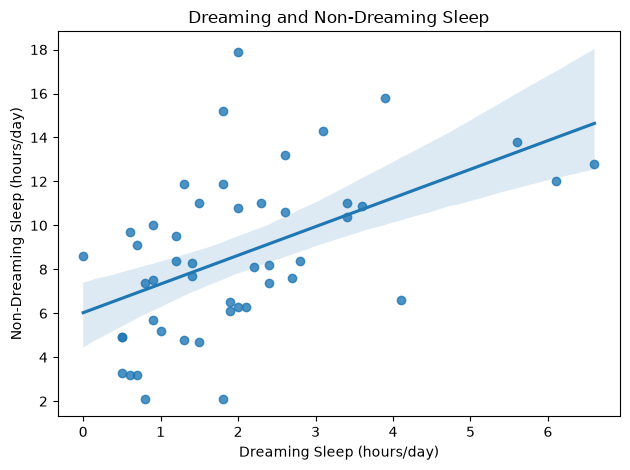

In [9]:
sns.regplot(data=sleep_df, x="dreaming_sleep", y="non_dreaming_sleep")
plt.title("Dreaming and Non-Dreaming Sleep")
plt.xlabel("Dreaming Sleep (hours/day)")
plt.ylabel("Non-Dreaming Sleep (hours/day)")
plt.tight_layout()
plt.show()

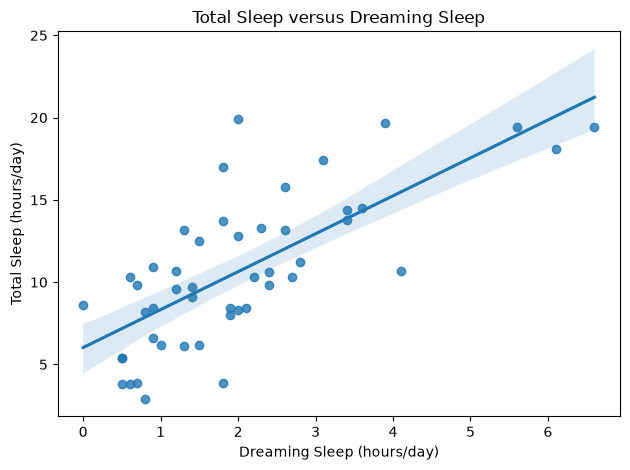

In [10]:
sns.regplot(data=sleep_df, x="dreaming_sleep", y="total_sleep")
plt.title("Total Sleep versus Dreaming Sleep")
plt.xlabel("Dreaming Sleep (hours/day)")
plt.ylabel("Total Sleep (hours/day)")
plt.tight_layout()
plt.show()

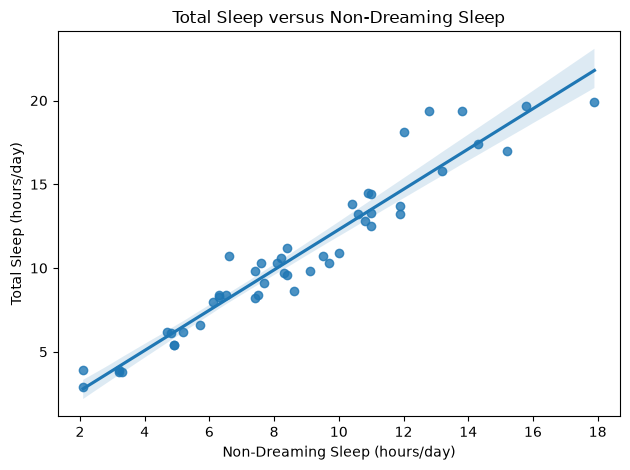

In [11]:
sns.regplot(data=sleep_df, x="non_dreaming_sleep", y="total_sleep")
plt.title("Total Sleep versus Non-Dreaming Sleep")
plt.xlabel("Non-Dreaming Sleep (hours/day)")
plt.ylabel("Total Sleep (hours/day)")
plt.tight_layout()
plt.show()

In [12]:
pairs = [
    ("dreaming_sleep", "non_dreaming_sleep"),
    ("dreaming_sleep", "total_sleep"),
    ("non_dreaming_sleep", "total_sleep")
]

results = []

for x, y in pairs:
    r = sleep_df[x].corr(sleep_df[y])
    results.append({
        "Horizontal feature": x,
        "Response": y,
        "Correlation": r,
        "R-squared": r ** 2
    })

pd.DataFrame(results).round(4)

,Horizontal feature,Response,Correlation,R-squared
0,dreaming_sleep,non_dreaming_sleep,0.5143,0.2645
1,dreaming_sleep,total_sleep,0.7271,0.5287
2,non_dreaming_sleep,total_sleep,0.9627,0.9268


**For each plot, do the points generally rise or fall? Is their pattern roughly straight or curved, and how closely do they follow it? Identify any unusual observations. Which plot is best summarized by a straight line? Explain what its R-squared tells you about total sleep.**

Your answer:All three relationships are positive: the points generally rise from left to right.

Dreaming versus non-dreaming sleep shows a roughly linear, moderate relationship with considerable scatter (r = 0.5143; R² = 0.2645). Unusual observations include a species near 2 hours of dreaming and 18 hours of non-dreaming sleep.

Dreaming versus total sleep shows a stronger, roughly linear relationship, but substantial scatter remains (r = 0.7271; R² = 0.5287). A point near 2 hours of dreaming and 20 hours of total sleep lies well above the fitted line.

Non-dreaming versus total sleep is best summarized by a straight line: its points follow a positive linear pattern closely (r = 0.9627; R² = 0.9268). Some species around 12–14 hours of non-dreaming sleep lie above the line.

For these 48 species, approximately 92.68% of the variation in total sleep around its mean is accounted for by the fitted linear relationship with non-dreaming sleep. This is an in-sample description, not a measure of prediction accuracy on new species or evidence of causation. The strong relationship also partly reflects that total sleep includes non-dreaming sleep.

## Step 4: Check

Check that `dreaming_sleep + non_dreaming_sleep` agrees with `total_sleep` using `np.isclose()`, which allows for ordinary floating-point rounding. Display several original rows with their phase sum. Then display the three records with the longest non-dreaming sleep and locate their points on the non-dreaming versus total sleep plot. Do the plotted values agree with the records?

In [13]:
phase_check_df = sleep_df[
    ["species", "dreaming_sleep", "non_dreaming_sleep", "total_sleep"]
].copy()

phase_check_df["phase_sum"] = (
    phase_check_df["dreaming_sleep"]
    + phase_check_df["non_dreaming_sleep"]
)

phase_check_df["matches_total"] = np.isclose(
    phase_check_df["phase_sum"],
    phase_check_df["total_sleep"]
)

display(phase_check_df.head())
print("All phase sums match:", phase_check_df["matches_total"].all())

display(phase_check_df.loc[~phase_check_df["matches_total"]])

,species,dreaming_sleep,non_dreaming_sleep,total_sleep,phase_sum,matches_total
1,African giant pouched rat,2.0,6.3,8.3,8.3,True
4,Asian elephant,1.8,2.1,3.9,3.9,True
5,Baboon,0.7,9.1,9.8,9.8,True
6,Big brown bat,3.9,15.8,19.7,19.7,True
7,Brazilian tapir,1.0,5.2,6.2,6.2,True


All phase sums match: True


,species,dreaming_sleep,non_dreaming_sleep,total_sleep,phase_sum,matches_total


In [14]:
longest_sleep_df = sleep_df.nlargest(3, "non_dreaming_sleep")

display(longest_sleep_df[
    ["species", "dreaming_sleep", "non_dreaming_sleep", "total_sleep"]
])

,species,dreaming_sleep,non_dreaming_sleep,total_sleep
32,Little brown bat,2.0,17.9,19.9
6,Big brown bat,3.9,15.8,19.7
41,Owl monkey,1.8,15.2,17.0


## Step 5: Conclusion

**Research question:** How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?

**Do mammals that spend more time in dreaming sleep also tend to spend more time in non-dreaming sleep? Which phase is more strongly related to total sleep? Support your answers with the plots, correlations, and R-squared values. Did the results match your prediction?**

Your answer:Among these 48 species, mammals with more dreaming sleep also tended to have more non-dreaming sleep, although the relationship showed considerable scatter (r = 0.5143; R² = 0.2645). Non-dreaming sleep had the stronger linear relationship with total sleep (r = 0.9627; R² = 0.9268), compared with dreaming sleep (r = 0.7271; R² = 0.5287). The non-dreaming-versus-total plot also showed points clustered more closely around a straight line.

## Step 6: Limitation

**State two limitations specific to these sleep relationships. Explain why a stronger correlation is not automatically a better scientific explanation.**

Your answer:First, total sleep is the sum of dreaming and non-dreaming sleep, so each phase is mathematically connected to the total. A stronger correlation therefore does not establish an independent causal explanation of sleep.

Second, the analysis uses 48 complete species records from a historical comparative dataset, excluding 14 species with missing required information. This subset may differ from excluded species and is not a random sample of all mammals. A stronger correlation describes a tighter linear association in these records, but does not by itself establish a better scientific explanation or reliable predictions for other species.

# Investigation 2: Do danger and predation add information?

## Step 1: Question

**Do danger and predation categories add information about total sleep beyond non-dreaming sleep?**

**Predict whether each index will add substantial, small, or little visible information. What would you look for at comparable non-dreaming-sleep durations?**

Your answer:I predict danger and predation categories will add little or only small visible information because non-dreaming sleep already has a very strong relationship with total sleep. At comparable non-dreaming durations, I would look for consistent vertical differences between categories. Large overlap would suggest little additional visible information. I am uncertain which index will show clearer differences.

## Step 2: Data

Reuse `sleep_df` and its original sleep measurements. Count records for each danger and predation rating and display a cross-tabulation of the two indices. Keep all five original levels in their natural order. Higher predation index values mean a mammal is more likely to be preyed upon. Higher danger index values mean greater overall danger from other animals.

In [15]:
rating_order = [1, 2, 3, 4, 5]

display(
    sleep_df["danger_index"].value_counts()
    .reindex(rating_order, fill_value=0)
)

display(
    sleep_df["predation_index"].value_counts()
    .reindex(rating_order, fill_value=0)
)

danger_index
1    14
2    12
3     8
4     9
5     5
Name: count, dtype: int64

predation_index
1    10
2    13
3     9
4     7
5     9
Name: count, dtype: int64

In [16]:
pd.crosstab(
    sleep_df["danger_index"],
    sleep_df["predation_index"]
).reindex(
    index=rating_order,
    columns=rating_order,
    fill_value=0
)

predation_index,1,2,3,4,5
danger_index,,,,,
1,10,4,0,0,0
2,0,9,3,0,0
3,0,0,5,2,1
4,0,0,1,5,3
5,0,0,0,0,5


## Step 3: Evidence

Use `sns.lmplot()` twice on the non-dreaming–total sleep relationship, once colored by `danger_index` and once by `predation_index`. Set `hue_order=[1, 2, 3, 4, 5]`, use a named palette, and label the legend so the index direction is clear. The separate lines show group patterns; small groups may produce unstable lines. Compare groups where their non-dreaming-sleep ranges overlap.

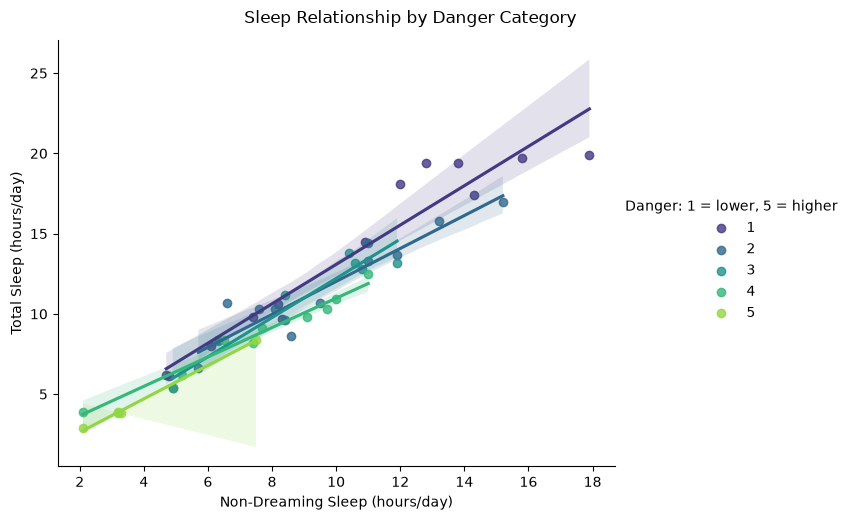

In [17]:
g = sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="danger_index",
    hue_order=rating_order,
    palette="viridis",
    height=5,
    aspect=1.3,
    legend=False
)

g.set_axis_labels(
    "Non-Dreaming Sleep (hours/day)",
    "Total Sleep (hours/day)"
)
g.fig.suptitle("Sleep Relationship by Danger Category", y=1.03)
g.add_legend(title="Danger: 1 = lower, 5 = higher")
plt.show()

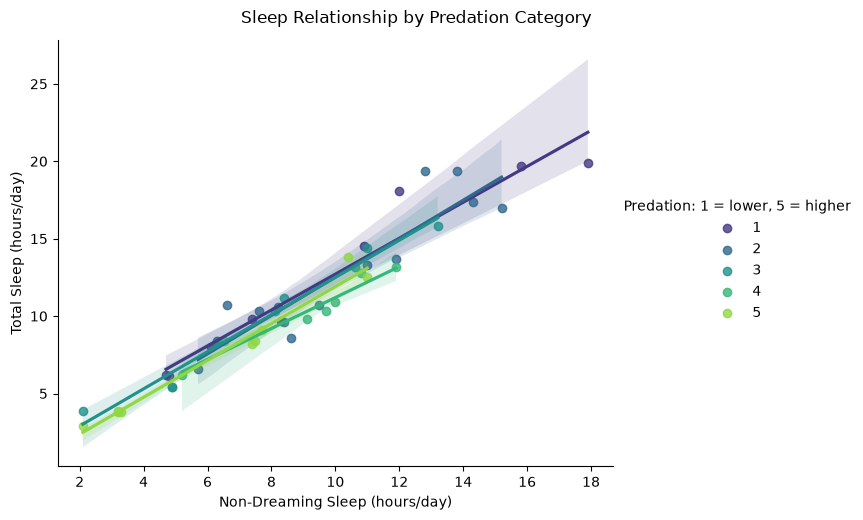

In [18]:
g = sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="predation_index",
    hue_order=rating_order,
    palette="viridis",
    height=5,
    aspect=1.3,
    legend=False
)

g.set_axis_labels(
    "Non-Dreaming Sleep (hours/day)",
    "Total Sleep (hours/day)"
)
g.fig.suptitle("Sleep Relationship by Predation Category", y=1.03)
g.add_legend(title="Predation: 1 = lower, 5 = higher")
plt.show()

**Describe overlap and separation in each plot. How do the group sizes and available non-dreaming-sleep ranges affect your interpretation?**

Your answer:In both plots, all categories generally follow the strong positive relationship between non-dreaming and total sleep. At comparable non-dreaming durations, the groups overlap substantially.

The danger plot suggests some vertical separation: lower-danger categories tend to have higher fitted total sleep than higher-danger categories in parts of their overlapping ranges. However, the differences are modest, and the highest-danger category covers a short horizontal range.

The predation plot shows considerable overlap among fitted lines, with no clear, consistently ordered separation across all five levels. Visually, danger appears to add somewhat clearer information than predation, but neither plot alone establishes a substantial improvement.

The categories cover different non-dreaming-sleep ranges, so differences at opposite ends of the plots are not comparisons at the same duration. Small groups can produce unstable fitted lines and wide uncertainty bands. I would interpret patterns mainly where observed ranges overlap and use the category counts to identify sparse groups.

Danger-category sizes are 14, 12, 8, 9, and 5 species for levels 1–5. Predation-category sizes are 10, 13, 9, 7, and 9. Danger level 5 has only five species, so its fitted line deserves particular caution. Predation level 4 is also small, with seven species.

The cross-tabulation shows strong overlap between the indices: all ten species with predation level 1 have danger level 1, and all five species with danger level 5 have predation level 5. Many combinations are absent. Therefore, the two indices may provide overlapping information rather than separate, independent explanations.

### Compare model R-squared

The supplied helper follows the lecture's least-squares calculation. Read and run it; you do not need to recreate its matrix operations. `pd.get_dummies()` represents each rating with category indicators. `drop_first=True` chooses a reference level. This avoids assuming equal distances between index values.

These are **additive models**: one shared slope for the quantitative predictor and category-specific intercept adjustments. They differ from the separate group slopes in `lmplot()`. Compare the baseline, baseline plus danger, baseline plus predation, and baseline plus both, all on identical rows and the same response scale. Training R-squared cannot decrease when predictors are added to these nested models; an increase alone does not establish improved performance on new observations.

In [19]:
def calculate_r_squared(data, predictor, response, categorical_features):
    predictors = pd.get_dummies(
        data[[predictor, *categorical_features]],
        columns=categorical_features, drop_first=True, dtype=float
    )
    predictors.insert(0, "intercept", 1.0)
    x = predictors.to_numpy(dtype=float)
    y = data[response].to_numpy(dtype=float)
    fitted = x @ np.linalg.lstsq(x, y, rcond=None)[0]
    return 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()

In [20]:
phase_comparison = pd.DataFrame({
    "Model": [
        "Non-dreaming only",
        "Non-dreaming + danger",
        "Non-dreaming + predation",
        "Non-dreaming + both"
    ],
    "R-squared": [
        calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", []
        ),
        calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep",
            ["danger_index"]
        ),
        calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep",
            ["predation_index"]
        ),
        calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep",
            ["danger_index", "predation_index"]
        )
    ]
})

phase_comparison["Increase over baseline"] = (
    phase_comparison["R-squared"]
    - phase_comparison.loc[0, "R-squared"]
)

phase_comparison.round(4)

,Model,R-squared,Increase over baseline
0,Non-dreaming only,0.9268,0.0000
1,Non-dreaming + danger,0.9427,0.0158
2,Non-dreaming + predation,0.9371,0.0103
3,Non-dreaming + both,0.9515,0.0246


## Step 4: Check

For each danger rating, display the smallest and largest non-dreaming sleep values using `.groupby()` and `.agg(["min", "max"])`. Repeat for predation ratings.

Compare these ranges with the group plots. Use the ranges to identify where two groups actually have observations at similar non-dreaming sleep durations.

In [21]:
print("Non-dreaming sleep ranges by danger category:")
display(
    sleep_df.groupby("danger_index")["non_dreaming_sleep"]
    .agg(["count", "min", "max"])
)

print("Non-dreaming sleep ranges by predation category:")
display(
    sleep_df.groupby("predation_index")["non_dreaming_sleep"]
    .agg(["count", "min", "max"])
)

Non-dreaming sleep ranges by danger category:


,count,min,max
danger_index,,,
1,14,4.7,17.9
2,12,5.7,15.2
3,8,4.9,11.9
4,9,2.1,11.0
5,5,2.1,7.5


Non-dreaming sleep ranges by predation category:


,count,min,max
predation_index,,,
1,10,4.7,17.9
2,13,5.7,15.2
3,9,2.1,13.2
4,7,5.2,11.9
5,9,2.1,11.0


**Choose two danger groups. Over what range of non-dreaming sleep do both groups have observations? Why should you compare their lines within that shared range?**

Your answer: Danger group 1 spans 4.7–17.9 hours of non-dreaming sleep, while group 2 spans 5.7–15.2 hours. Their observed ranges overlap from 5.7 to 15.2 hours per day. I should compare their fitted lines within this shared range because both groups have supporting observations there. Outside it, one group’s line would require extrapolation. Overlapping ranges do not mean observations occur at every duration, so local sparsity still deserves caution.

## Step 5: Conclusion

**Research question:** Do danger and predation categories add information about total sleep beyond non-dreaming sleep?

**Does adding danger, predation, or both improve the model of total sleep? Report the four R-squared values and how much each changes from non-dreaming sleep alone. Are the improvements small or large? Explain how the group plots support your answer.**

Your answer:Adding the categories improved training fit slightly. R-squared was 0.9268 for non-dreaming sleep alone, 0.9427 with danger added, 0.9371 with predation added, and 0.9515 with both. Using the unrounded calculations, increases over baseline were approximately 0.0158, 0.0103, and 0.0246, respectively.

Danger added more information than predation when considered separately. The group plots support modest improvements: categories overlap substantially, but the danger plot shows some vertical separation at comparable non-dreaming durations. These are improvements in fit to the existing records, not demonstrated improvements in prediction for new species.

## Step 6: Limitation

**Identify two limitations of this investigation.**

Your answer:First, there are only 48 species, some category groups are small, and their non-dreaming-sleep ranges differ. This makes group lines uncertain and limits comparisons outside shared observed ranges.

Second, danger and predation contain overlapping information, and adding category predictors increases model complexity. Training R-squared cannot decrease for these nested models, so its increase alone does not demonstrate independent effects, causation, or improved performance on new observations.

# Investigation 3: Gestation time and total sleep

## Step 1: Question

**How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?**

Gestation time is the length of a pregnancy, measured in days. We will compare it with total sleep, measured in hours per day, and see whether taking the logarithm of gestation time makes the pattern look straighter.

**Do you expect mammals with longer pregnancies to sleep more hours per day, fewer hours, or about the same amount? Explain your initial guess. You do not need prior knowledge about mammals; you will compare your prediction with the data.**

Your answer:I predict species with longer gestation times will tend to sleep fewer hours per day. My initial guess is that species with shorter pregnancies may have different activity and energy-use patterns. I am uncertain how strong or straight the relationship will be, and I will compare this prediction with the observed data.

## Step 2: Data

Create `gestation_df` by dropping rows missing `gestation_time`, `total_sleep`, `danger_index`, or `predation_index`, then copying the result. How many records were removed from the dataset? Do not drop rows merely because maximum lifespan is missing. Check that gestation is positive and sleep is between 0 and 24 hours per day. Create `log10_gestation_time` only after checking the inputs.

In [22]:
gestation_df = mammals_df.dropna(subset=[
    "gestation_time", "total_sleep",
    "danger_index", "predation_index"
]).copy()

print("Original records:", len(mammals_df))
print("Complete records:", len(gestation_df))
print("Records removed:", len(mammals_df) - len(gestation_df))

display(
    gestation_df[["gestation_time", "total_sleep"]].agg(["min", "max"])
)

valid_gestation = gestation_df["gestation_time"].gt(0).all()
valid_sleep = gestation_df["total_sleep"].between(0, 24).all()

print("All gestation times positive:", valid_gestation)
print("All sleep values within 0–24:", valid_sleep)

if valid_gestation and valid_sleep:
    gestation_df["log10_gestation_time"] = np.log10(
        gestation_df["gestation_time"]
    )
else:
    raise ValueError("Inspect invalid measurements before continuing.")

Original records: 62
Complete records: 54
Records removed: 8


,gestation_time,total_sleep
min,12.0,2.6
max,645.0,19.9


All gestation times positive: True
All sleep values within 0–24: True


## Step 3: Evidence

Plot sleep against gestation on original scales, then against log10 gestation, leaving sleep in hours per day. Calculate correlation and simple-line R-squared for each. These R-squared values share the same response scale and observations. Compare whether the points follow a straight or curved pattern and how widely they are scattered, as well as the numerical summaries.

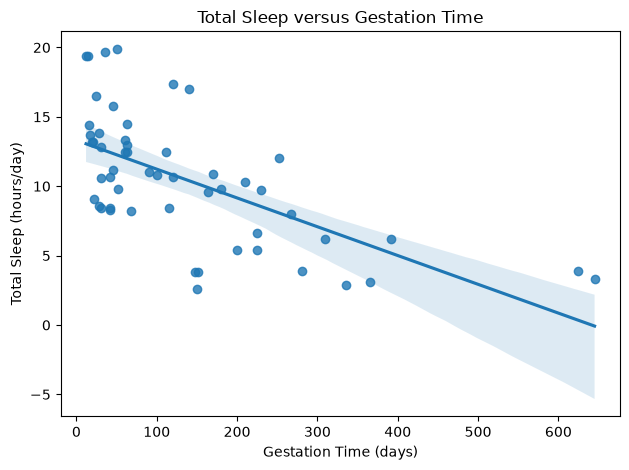

In [23]:
sns.regplot(data=gestation_df, x="gestation_time", y="total_sleep")
plt.title("Total Sleep versus Gestation Time")
plt.xlabel("Gestation Time (days)")
plt.ylabel("Total Sleep (hours/day)")
plt.tight_layout()
plt.show()

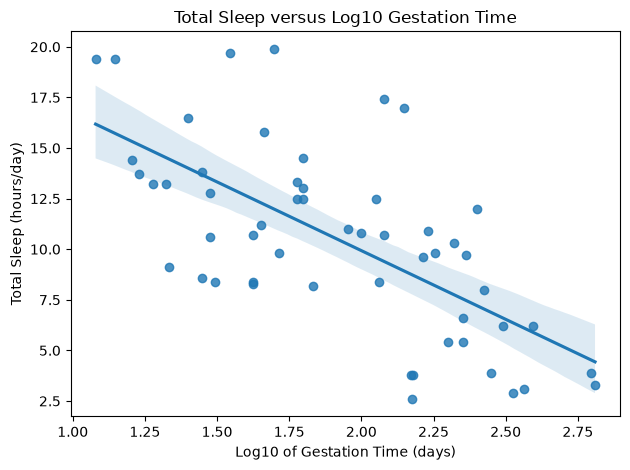

In [24]:
sns.regplot(data=gestation_df, x="log10_gestation_time", y="total_sleep")
plt.title("Total Sleep versus Log10 Gestation Time")
plt.xlabel("Log10 of Gestation Time (days)")
plt.ylabel("Total Sleep (hours/day)")
plt.tight_layout()
plt.show()

In [25]:
gestation_results = []

for predictor in ["gestation_time", "log10_gestation_time"]:
    r = gestation_df[predictor].corr(gestation_df["total_sleep"])
    gestation_results.append({
        "Predictor": predictor,
        "Correlation": r,
        "R-squared": r ** 2
    })

pd.DataFrame(gestation_results).round(4)

,Predictor,Correlation,R-squared
0,gestation_time,-0.6313,0.3986
1,log10_gestation_time,-0.6637,0.4404


**What changes when gestation is log-transformed? Does the transformation remove the scatter or only improve the straight-line summary modestly?**

Your answer:The log transformation spreads out shorter gestation times and compresses longer ones, making the downward pattern somewhat straighter. Substantial scatter remains, so the transformation improves the straight-line summary modestly rather than removing variability.

The correlation changes from −0.6313 to −0.6637, while R-squared increases from 0.3986 to 0.4404—an increase of 0.0418, or 4.18 percentage points of variation accounted for. Both plots show that species with longer gestation times tend to have less total sleep in this dataset. These associations do not establish causation.

Reuse the group-plot and model-comparison approach from Investigation 2, now using `log10_gestation_time` as the predictor and `total_sleep` as the response. Count observations at each rating level in this subset before interpreting the group lines. Examine danger and predation separately, then compare all four additive models on `gestation_df`.

In [26]:
rating_order = [1, 2, 3, 4, 5]

for feature in ["danger_index", "predation_index"]:
    print(feature)
    display(
        gestation_df[feature].value_counts()
        .reindex(rating_order, fill_value=0)
    )

danger_index


danger_index
1    16
2    12
3    10
4     9
5     7
Name: count, dtype: int64

predation_index


predation_index
1    12
2    14
3     9
4     7
5    12
Name: count, dtype: int64

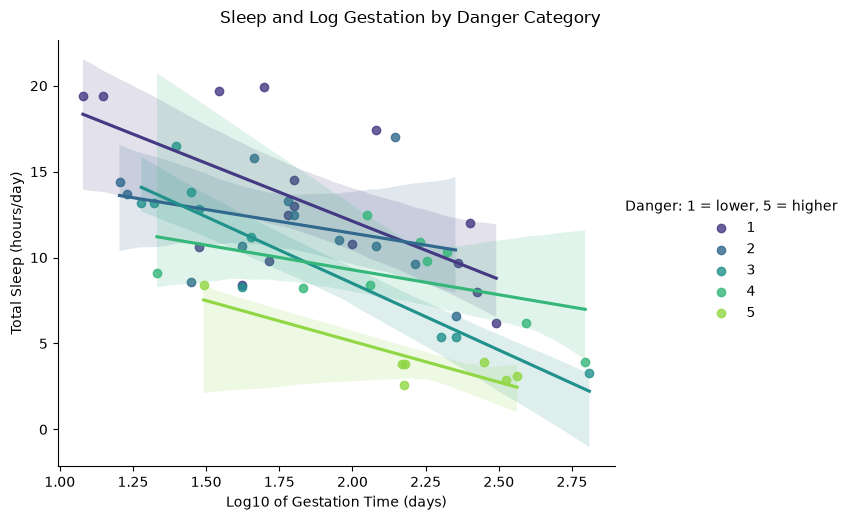

In [27]:
g = sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time", y="total_sleep",
    hue="danger_index", hue_order=rating_order,
    palette="viridis", height=5, aspect=1.3,
    legend=False
)
g.set_axis_labels(
    "Log10 of Gestation Time (days)", "Total Sleep (hours/day)"
)
g.fig.suptitle("Sleep and Log Gestation by Danger Category", y=1.03)
g.add_legend(title="Danger: 1 = lower, 5 = higher")
plt.show()

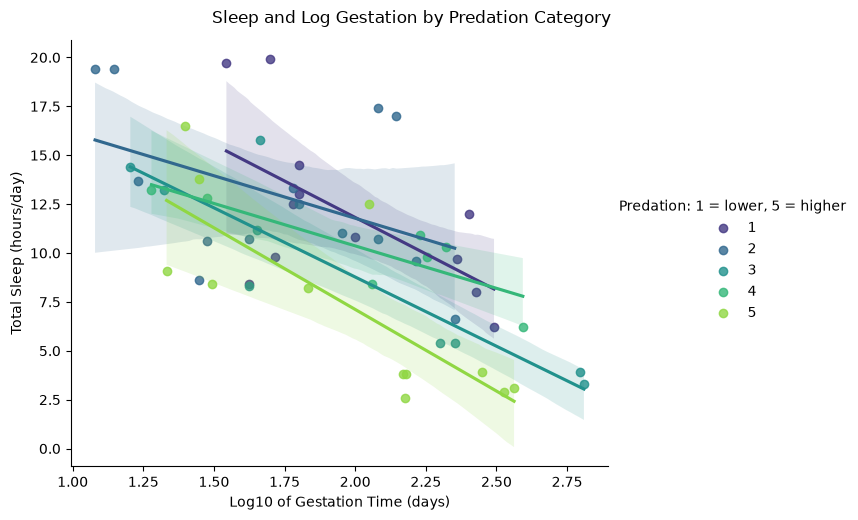

In [28]:
g = sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time", y="total_sleep",
    hue="predation_index", hue_order=rating_order,
    palette="viridis", height=5, aspect=1.3,
    legend=False
)
g.set_axis_labels(
    "Log10 of Gestation Time (days)", "Total Sleep (hours/day)"
)
g.fig.suptitle("Sleep and Log Gestation by Predation Category", y=1.03)
g.add_legend(title="Predation: 1 = lower, 5 = higher")
plt.show()

In [29]:
sleep_comparison = pd.DataFrame({
    "Model": [
        "Log gestation only",
        "Log gestation + danger",
        "Log gestation + predation",
        "Log gestation + both"
    ],
    "R-squared": [
        calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", []
        ),
        calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep",
            ["danger_index"]
        ),
        calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep",
            ["predation_index"]
        ),
        calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep",
            ["danger_index", "predation_index"]
        )
    ]
})

sleep_comparison["Increase over baseline"] = (
    sleep_comparison["R-squared"]
    - sleep_comparison.loc[0, "R-squared"]
)

sleep_comparison.round(4)

,Model,R-squared,Increase over baseline
0,Log gestation only,0.4404,0.0000
1,Log gestation + danger,0.6542,0.2137
2,Log gestation + predation,0.5917,0.1512
3,Log gestation + both,0.6943,0.2538


## Step 4: Check

For the first five records, display gestation time, its logarithm, and `10 ** log10_gestation_time`. Does reversing the logarithm recover the original number of days?

Display the records with the shortest and longest gestation times. Find their points in both plots and compare the recorded sleep hours with their vertical positions. The horizontal positions change when gestation is transformed; the sleep measurements stay the same.

In [30]:
log_check_df = gestation_df[
    ["species", "gestation_time", "log10_gestation_time"]
].head().copy()

log_check_df["recovered_days"] = (
    10 ** log_check_df["log10_gestation_time"]
)

log_check_df["matches_original"] = np.isclose(
    log_check_df["gestation_time"],
    log_check_df["recovered_days"]
)

log_check_df

,species,gestation_time,log10_gestation_time,recovered_days,matches_original
0,African elephant,645.0,2.809560,645.0,True
1,African giant pouched rat,42.0,1.623249,42.0,True
2,Arctic Fox,60.0,1.778151,60.0,True
3,Arctic ground squirrel,25.0,1.397940,25.0,True
4,Asian elephant,624.0,2.795185,624.0,True


In [31]:
extreme_columns = [
    "species", "gestation_time",
    "log10_gestation_time", "total_sleep"
]

display(gestation_df.nsmallest(1, "gestation_time")[extreme_columns])
display(gestation_df.nlargest(1, "gestation_time")[extreme_columns])

,species,gestation_time,log10_gestation_time,total_sleep
38,N. American opossum,12.0,1.079181,19.4


,species,gestation_time,log10_gestation_time,total_sleep
0,African elephant,645.0,2.80956,3.3


**Did reversing the logarithm recover the original gestation times? For the shortest and longest gestation records, do both plots show the recorded total sleep values? Describe what changed between the plots and what stayed the same.**

Your answer:Yes. Raising 10 to log10_gestation_time recovered the original gestation times for all five checked records within floating-point tolerance.

The shortest-gestation record is the N. American opossum: 12 days and 19.4 hours of total sleep. Its horizontal position changes from 12 to approximately 1.079 after transformation, while its sleep value remains 19.4 hours.

The longest-gestation record is the African elephant: 645 days and 3.3 hours of sleep. Its horizontal position changes from 645 to approximately 2.810, while its sleep value remains 3.3 hours. Both plots agree with these recorded sleep values. Only the gestation scale changes.

## Step 5: Conclusion

**Research question:** How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?

**Do mammals with longer gestation times tend to sleep more or less? Does using log gestation make the pattern look straighter? Do danger and predation add information? Support your answers with the plots, correlation, and R-squared values, and compare the results with your prediction.**

Your answer:Species with longer gestation times tended to sleep fewer hours per day. On the original scale, correlation was −0.6313 and R² was 0.3986. Using log10 gestation made the pattern somewhat straighter, with correlation −0.6637 and R² 0.4404, although substantial scatter remained.

Danger and predation added information to the fitted models. R² increased to 0.6542 with danger, 0.5917 with predation, and 0.6943 with both. Increases over the log-gestation baseline were approximately 0.2137, 0.1512, and 0.2538. The group plots showed some vertical separation at comparable gestation times, alongside overlap and uncertainty. These are improvements in training fit, not demonstrated improvements in prediction for new species.

## Step 6: Limitation

**Identify two limitations of the gestation and sleep investigation.**

Your answer:First, this historical dataset is not a random sample of all mammals, and excluding records with missing required measurements may affect the findings. Species also differ in body size, ecology, and evolutionary relationships, so the associations do not establish causation.

Second, some rating groups are small, and danger and predation contain overlapping information. Adding predictors can increase training R² without improving predictions for new species. Comparisons are also less reliable where groups have little overlap in gestation times.

## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:I used ChatGPT to explain code, interpret plots, and draft written responses. One suggestion I checked was reversing the log10 transformation using 10 raised to the transformed value. My output recovered the original gestation times for all five checked records within floating-point tolerance. I accepted the transformation after this check and confirmed that sleep remained in hours per day. I also checked numerical interpretations against my displayed correlations and model results.

## Submission checklist

- Use the supplied CSV with a relative path.
- Complete the dictionary table and every written response.
- Include a prediction and all six workflow steps for each investigation.
- Include all three sleep comparison plots, two non-dreaming–total group plots, original and log-gestation sleep plots, and two sleep group plots.
- Keep observations consistent within each comparison; report counts and investigate exclusions.
- Interpret correlation and R-squared on the correct scale, using numerical and visual evidence.
- Compare baseline, danger, predation, and combined models without claiming automatic causal or predictive improvement.
- Explain whether the patterns are straight or curved, how the log transformation changes the gestation plot, and what the analyses cannot tell us.
- Complete the AI-use reflection, restart the kernel, and run the notebook in order before submitting.